# 試算例: APF の内訳と感度の分析

本 Notebook は、計算プログラム `jis_c9612` を用いて、いくつかの検討ケースの APF を試算し、分析する。
結果の図と表は `docs/case_studies/` に保存し、ドキュメント 6 章「試算例」で用いる。

- 入力値は説明用の例であり、特定の機種の値ではない (ドキュメント 3 章の図の例と同じ)。
- 実行するには、conda 環境 `JIS_C9612` をカーネルに選び、上から順にすべてのセルを実行する。

検討するケースは次のとおりである。

1. 基準ケースの内訳 (運転状態ごとの時間・空調負荷・消費電力量)
2. 入力値の感度分析 (入力値を 1 つずつ ±10 % 変える)
3. 能力の規模 (すべての値を比例させて 2.2〜5.6 kW にする)
4. 外気温度の分布 (東京の分布を暑い側・寒い側にずらす)
5. 最大モードの有無 (ドキュメント 4 章の暫定の扱いの影響)

In [1]:
# 試算に用いるモジュールを読み込む
import logging
from collections import defaultdict
from dataclasses import fields, replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from jis_c9612 import CoolingInput, HeatingInput, compute_apf
from jis_c9612.climate import TOKYO_COOLING_HOURS, TOKYO_HEATING_HOURS

# 図と表の保存先 (ドキュメント 6 章で読み込む)
OUT = Path("..") / "docs" / "case_studies"
OUT.mkdir(parents=True, exist_ok=True)

# 図の配色と体裁 (ドキュメント 3 章の図と同じ。文字は SVG のテキストとして出力する)
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
# フォントの候補は固定する (SVG に書き込まれ、見る側のブラウザが使えるフォントで表示する)。
# この PC に入っていない候補があると matplotlib が通知を出すので、その通知は表示しない
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams.update({
    "font.family": ["Hiragino Sans", "Hiragino Kaku Gothic ProN", "Noto Sans CJK JP", "sans-serif"],
    "font.size": 10,
    "svg.fonttype": "none",
    "svg.hashsalt": "jis-c9612",
    "axes.edgecolor": INK_2,
    "axes.labelcolor": INK,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
})


def style(ax):
    # 目盛り線を薄く、上と右の枠を消す
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):

        ax.spines[side].set_visible(False)


def save(fig, name):
    # 図を SVG で保存する (作成日時を入れず、作り直しても差分が出ないようにする)
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.svg", metadata={"Date": None})


def save_table(df, name):
    # 表を CSV で保存する (ドキュメントの csv-table で読み込む)
    df.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8")

## 基準ケース

基準ケースの入力値を定める。定格冷房能力 2.8 kW、最大モードをもつ機種とする。

In [2]:
# 基準ケースの入力値 (W)
BASE_C = CoolingInput(phi_c_ful_t100=2800, phi_c_ful_35=2800, p_c_ful_35=700, phi_c_haf_35=1400, p_c_haf_35=280)
BASE_H = HeatingInput(
    phi_c_ful_t100=2800, phi_h_ful_7=3600, p_h_ful_7=900, phi_h_haf_7=1800, p_h_haf_7=360,
    phi_h_ext_f_2=4200, p_h_ext_f_2=1500,
)

# 基準ケースを計算する
base = compute_apf(BASE_C, BASE_H)

# 入力値と、試験条件でのエネルギー消費効率を表にする
inputs = pd.DataFrame([
    ("冷房", "定格運転 (外気 35 ℃)", BASE_C.phi_c_ful_35, BASE_C.p_c_ful_35),
    ("冷房", "中間運転 (外気 35 ℃)", BASE_C.phi_c_haf_35, BASE_C.p_c_haf_35),
    ("暖房", "定格運転 (外気 7 ℃)", BASE_H.phi_h_ful_7, BASE_H.p_h_ful_7),
    ("暖房", "中間運転 (外気 7 ℃)", BASE_H.phi_h_haf_7, BASE_H.p_h_haf_7),
    ("暖房", "最大運転 (外気 2 ℃、着霜時)", BASE_H.phi_h_ext_f_2, BASE_H.p_h_ext_f_2),
], columns=["期間", "運転", "能力 (W)", "消費電力 (W)"])
inputs["効率 (−)"] = (inputs["能力 (W)"] / inputs["消費電力 (W)"]).map(lambda v: f"{v:.2f}")
save_table(inputs, "tab_inputs")
inputs

,期間,運転,能力 (W),消費電力 (W),効率 (−)
0,冷房,定格運転 (外気 35 ℃),2800,700,4.00
1,冷房,中間運転 (外気 35 ℃),1400,280,5.00
2,暖房,定格運転 (外気 7 ℃),3600,900,4.00
3,暖房,中間運転 (外気 7 ℃),1800,360,5.00
4,暖房,最大運転 (外気 2 ℃、着霜時),4200,1500,2.80


In [3]:
# 基準ケースの結果
pd.Series({
    "APF": base.f_ap, "CSPF": base.cooling.f_csp, "HSPF": base.heating.f_hsp,
    "CSTL (kWh)": base.cooling.l_cst / 1e3, "CSEC (kWh)": base.cooling.c_cse / 1e3,
    "HSTL (kWh)": base.heating.l_hst / 1e3, "HSEC (kWh)": base.heating.c_hse / 1e3,
}).round(3)

APF              4.798
CSPF             5.434
HSPF             4.536
CSTL (kWh)    1748.833
CSEC (kWh)     321.815
HSTL (kWh)    3547.320
HSEC (kWh)     782.045
dtype: float64

## ケース 1: 基準ケースの内訳

運転状態ごとに、発生時間、処理する空調負荷、消費電力量を集計し、期間全体に対する割合を求める。

In [4]:
# 運転状態ごとに、発生時間・処理する空調負荷・消費電力量を集計する
def breakdown(bins, n, q, p, period):

    total = defaultdict(lambda: [0.0, 0.0, 0.0])
    for b in bins:

        h = getattr(b, n)
        t = total[b.state.value]
        t[0] += h
        t[1] += getattr(b, q) * h
        t[2] += getattr(b, p) * h

    order = ["断続運転", "可変運転", "中間〜定格の可変運転", "定格〜最大の可変運転", "定格運転", "最大運転"]
    states = sorted(total, key=order.index)
    df = pd.DataFrame([(period, s, *total[s]) for s in states],
                      columns=["期間", "運転状態", "時間 (h)", "空調負荷 (kWh)", "消費電力量 (kWh)"])
    df["空調負荷 (kWh)"] /= 1e3
    df["消費電力量 (kWh)"] /= 1e3

    # 期間全体に対する割合と、運転状態ごとの効率 (空調負荷 / 消費電力量) を求める
    for col in ("時間 (h)", "空調負荷 (kWh)", "消費電力量 (kWh)"):

        df[col.split(" ")[0] + "の割合"] = df[col] / df[col].sum()

    df["効率 (−)"] = df["空調負荷 (kWh)"] / df["消費電力量 (kWh)"].where(df["消費電力量 (kWh)"] > 0)
    return df


bd_c = breakdown(base.cooling.bins, "n_c_j", "q_c", "p_c", "冷房")
bd_h = breakdown(base.heating.bins, "n_h_j", "q_h", "p_h", "暖房")
bd = pd.concat([bd_c, bd_h], ignore_index=True)
bd

,期間,運転状態,時間 (h),空調負荷 (kWh),消費電力量 (kWh),時間の割合,空調負荷の割合,消費電力量の割合,効率 (−)
0,冷房,断続運転,1145.0,950.833333,168.713923,0.729764,0.543696,0.524258,5.635773
1,冷房,可変運転,424.0,798.000000,153.101061,0.270236,0.456304,0.475742,5.212243
2,冷房,定格運転,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
3,暖房,断続運転,2096.0,2280.974706,483.931860,0.774289,0.643014,0.618803,4.713421
4,暖房,中間〜定格の可変運転,609.0,1260.605294,296.395145,0.224972,0.355368,0.379000,4.253124
5,暖房,定格〜最大の可変運転,2.0,5.740000,1.718069,0.000739,0.001618,0.002197,3.340960
6,暖房,最大運転,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,NaN


In [5]:
# ドキュメント用の表: 発生時間がある運転状態だけを、割合を % で示す
tab = bd[bd["時間 (h)"] > 0].copy()
tab_out = pd.DataFrame({
    "期間": tab["期間"],
    "運転状態": tab["運転状態"],
    "時間 (h)": tab["時間 (h)"].map(lambda v: f"{v:,.0f}"),
    "時間の割合": tab["時間の割合"].map(lambda v: f"{v:.1%}"),
    "空調負荷の割合": tab["空調負荷の割合"].map(lambda v: f"{v:.1%}"),
    "消費電力量の割合": tab["消費電力量の割合"].map(lambda v: f"{v:.1%}"),
    "効率 (−)": tab["効率 (−)"].map(lambda v: f"{v:.2f}"),
})
save_table(tab_out, "tab_breakdown")
tab_out

,期間,運転状態,時間 (h),時間の割合,空調負荷の割合,消費電力量の割合,効率 (−)
0,冷房,断続運転,"1,145",73.0%,54.4%,52.4%,5.64
1,冷房,可変運転,424,27.0%,45.6%,47.6%,5.21
3,暖房,断続運転,"2,096",77.4%,64.3%,61.9%,4.71
4,暖房,中間〜定格の可変運転,609,22.5%,35.5%,37.9%,4.25
5,暖房,定格〜最大の可変運転,2,0.1%,0.2%,0.2%,3.34


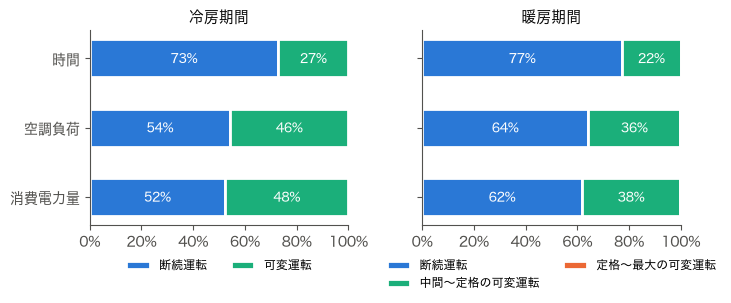

In [6]:
# 図: 期間ごとに、時間・空調負荷・消費電力量の割合を運転状態で積み上げる
STATE_COLORS = {
    "断続運転": BLUE, "可変運転": AQUA, "定格運転": ORANGE,
    "中間〜定格の可変運転": AQUA, "定格〜最大の可変運転": ORANGE, "最大運転": YELLOW,
}
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.2), sharey=True)
for ax, (period, df) in zip(axes, (("冷房期間", bd_c), ("暖房期間", bd_h))):

    df = df[df["時間 (h)"] > 0]
    labels = ["時間", "空調負荷", "消費電力量"]
    left = [0.0, 0.0, 0.0]
    for _, row in df.iterrows():

        vals = [row["時間の割合"], row["空調負荷の割合"], row["消費電力量の割合"]]
        ax.barh(labels, vals, left=left, color=STATE_COLORS[row["運転状態"]], height=0.55,
                edgecolor="white", linewidth=2, label=row["運転状態"])

        # 割合が 10 % 以上の区間に、値を直接書く
        for i, v in enumerate(vals):

            if v >= 0.10:

                ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)

        left = [a + b for a, b in zip(left, vals)]

    ax.set_title(period, color=INK, fontsize=10.5)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    style(ax)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=8.5)

# 縦軸は左右で共有しているので、上下の反転は 1 回だけ行う (時間を上にする)
axes[0].invert_yaxis()
save(fig, "fig_breakdown")

## ケース 2: 入力値の感度分析

入力値を 1 つずつ基準ケースから −10 %、+10 % 変え、APF の変化率を求める。
中間運転能力は、定格能力 (表示値) の 45 %〜55 % の範囲 (附属書 B の B.1.5.3.1、B.2.5.3.1) に収まる。

In [7]:
# 変える入力値と、表・図に表示する名前
PARAMS = [
    ("c", "phi_c_ful_35", "冷房 定格運転能力 Φc,ful(35)"),
    ("c", "p_c_ful_35", "冷房 定格運転消費電力 Pc,ful(35)"),
    ("c", "phi_c_haf_35", "冷房 中間運転能力 Φc,haf(35)"),
    ("c", "p_c_haf_35", "冷房 中間運転消費電力 Pc,haf(35)"),
    ("h", "phi_h_ful_7", "暖房 定格運転能力 Φh,ful(7)"),
    ("h", "p_h_ful_7", "暖房 定格運転消費電力 Ph,ful(7)"),
    ("h", "phi_h_haf_7", "暖房 中間運転能力 Φh,haf(7)"),
    ("h", "p_h_haf_7", "暖房 中間運転消費電力 Ph,haf(7)"),
    ("h", "phi_h_ext_f_2", "暖房 最大運転能力 Φh,ext,f(2)"),
    ("h", "p_h_ext_f_2", "暖房 最大運転消費電力 Ph,ext,f(2)"),
]


# 1 つの入力値に係数を掛けたときの APF を求める
def apf_with(side, key, factor):

    c, h = BASE_C, BASE_H
    if side == "c":

        c = replace(BASE_C, **{key: getattr(BASE_C, key) * factor})

    else:

        h = replace(BASE_H, **{key: getattr(BASE_H, key) * factor})

    return compute_apf(c, h).f_ap


rows = []
for side, key, label in PARAMS:

    rows.append((label, apf_with(side, key, 0.9) / base.f_ap - 1, apf_with(side, key, 1.1) / base.f_ap - 1))

# 変化率を符号付きの % で表す (0.005 % 未満は 0.00% とする)
def pct(v):

    return "0.00%" if abs(v) < 0.00005 else f"{v:+.2%}"


sens = pd.DataFrame(rows, columns=["入力値", "−10 %", "+10 %"])
sens["影響の大きさ"] = sens[["−10 %", "+10 %"]].abs().max(axis=1)
sens = sens.sort_values("影響の大きさ", ascending=False, ignore_index=True)

save_table(pd.DataFrame({
    "入力値": sens["入力値"],
    "−10 %": sens["−10 %"].map(pct),
    "+10 %": sens["+10 %"].map(pct),
}), "tab_sensitivity")
sens

,入力値,−10 %,+10 %,影響の大きさ
0,"暖房 中間運転消費電力 Ph,haf(7)",0.065440,-0.057013,0.065440
1,"暖房 中間運転能力 Φh,haf(7)",-0.057610,0.056039,0.057610
2,"冷房 中間運転消費電力 Pc,haf(35)",0.026311,-0.024567,0.026311
3,"冷房 中間運転能力 Φc,haf(35)",-0.025342,0.024011,0.025342
4,"暖房 定格運転能力 Φh,ful(7)",-0.019143,0.011619,0.019143
5,"暖房 定格運転消費電力 Ph,ful(7)",0.010528,-0.009366,0.010528
6,"冷房 定格運転能力 Φc,ful(35)",-0.007943,0.004652,0.007943
7,"冷房 定格運転消費電力 Pc,ful(35)",0.004007,-0.003526,0.004007
8,"暖房 最大運転能力 Φh,ext,f(2)",-0.000045,0.000023,0.000045
9,"暖房 最大運転消費電力 Ph,ext,f(2)",0.000019,-0.000016,0.000019


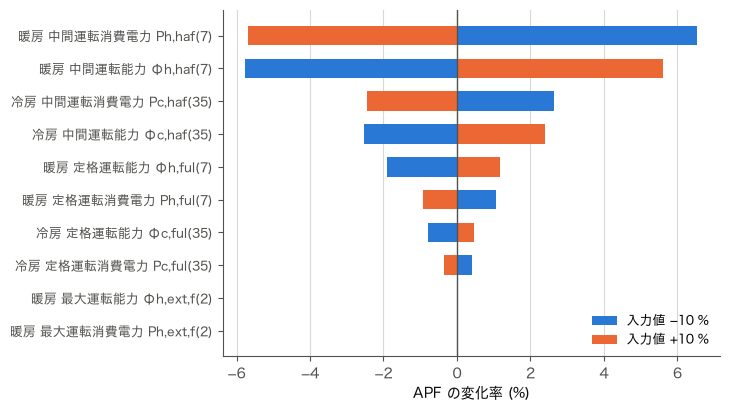

In [8]:
# 図: 感度の大きい順に、APF の変化率を横棒で示す (トルネード図)
fig, ax = plt.subplots(figsize=(7.4, 4.2))
y = range(len(sens))
ax.barh(y, sens["−10 %"] * 100, color=BLUE, height=0.6, label="入力値 −10 %")
ax.barh(y, sens["+10 %"] * 100, color=ORANGE, height=0.6, label="入力値 +10 %")
ax.set_yticks(list(y), sens["入力値"], fontsize=9)
ax.invert_yaxis()
ax.axvline(0, color=INK_2, lw=1)
ax.set_xlabel("APF の変化率 (%)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):

    ax.spines[side].set_visible(False)

ax.legend(loc="lower right", frameon=False, fontsize=9)
save(fig, "fig_sensitivity")

## ケース 3: 能力の規模

基準ケースのすべての値 (定格冷房能力、試験値)を同じ比率で拡大・縮小し、定格冷房能力 2.2 kW、4.0 kW、5.6 kW の機種を作る。

In [9]:
# すべての値に同じ係数を掛けた入力値を作る
def scaled(inp, k):

    return replace(inp, **{f.name: getattr(inp, f.name) * k for f in fields(inp) if getattr(inp, f.name) is not None})


rows = []
for kw in (2.2, 2.8, 4.0, 5.6):

    k = kw * 1000 / BASE_C.phi_c_ful_t100
    r = compute_apf(scaled(BASE_C, k), scaled(BASE_H, k))
    rows.append((f"{kw:.1f}", r.f_ap, r.cooling.f_csp, r.heating.f_hsp, r.annual_energy / 1e3))

scale = pd.DataFrame(rows, columns=["定格冷房能力 (kW)", "APF", "CSPF", "HSPF", "期間消費電力量 (kWh)"])
save_table(pd.DataFrame({
    "定格冷房能力 (kW)": scale["定格冷房能力 (kW)"],
    "APF": scale["APF"].map(lambda v: f"{v:.3f}"),
    "CSPF": scale["CSPF"].map(lambda v: f"{v:.3f}"),
    "HSPF": scale["HSPF"].map(lambda v: f"{v:.3f}"),
    "期間消費電力量 (kWh)": scale["期間消費電力量 (kWh)"].map(lambda v: f"{v:,.1f}"),
}), "tab_scale")
scale

,定格冷房能力 (kW),APF,CSPF,HSPF,期間消費電力量 (kWh)
0,2.2,4.797849,5.434282,4.535953,867.318617
1,2.8,4.797849,5.434282,4.535953,1103.860058
2,4.0,4.797849,5.434282,4.535953,1576.942939
3,5.6,4.797849,5.434282,4.535953,2207.720115


## ケース 4: 外気温度の分布

東京の外気温度の発生時間 (附属書 B の表 B.3、表 B.6) を、温度軸方向に平行移動する。
冷房期間は暑い側に 1〜3 ℃、暖房期間は寒い側に 2〜8 ℃ずらす。想定空調負荷の式 (負荷 0 %・100 %の外気温度)は変えない。
これは特定地域の分布を簡易に模擬したものであり、実在の地域の値ではない。

In [10]:
# 発生時間の分布を外気温度方向にずらす
def shifted(hours, d):

    return {t + d: n for t, n in hours.items()}


# 補助電熱装置の消費電力量 (kWh)
def heater_kwh(r):

    return sum(b.p_h_rh * b.n_h_j for b in r.heating.bins) / 1e3


rows = []
for d in (0, 1, 2, 3):

    r = compute_apf(BASE_C, BASE_H, shifted(TOKYO_COOLING_HOURS, d), None)
    rows.append(("冷房", f"{d:+d}", r.f_ap, r.cooling.f_csp, r.heating.f_hsp, r.cooling.l_cst / 1e3, r.cooling.c_cse / 1e3, 0.0))

for d in (-2, -4, -6, -8):

    r = compute_apf(BASE_C, BASE_H, None, shifted(TOKYO_HEATING_HOURS, d))
    rows.append(("暖房", f"{d:+d}", r.f_ap, r.cooling.f_csp, r.heating.f_hsp, r.heating.l_hst / 1e3, r.heating.c_hse / 1e3, heater_kwh(r)))

climate = pd.DataFrame(rows, columns=["ずらした期間", "ずらした温度 (℃)", "APF", "CSPF", "HSPF",
                                      "期間総合空調負荷 (kWh)", "期間消費電力量 (kWh)", "補助電熱装置 (kWh)"])
save_table(pd.DataFrame({
    "ずらした期間": climate["ずらした期間"],
    "ずらした温度 (℃)": climate["ずらした温度 (℃)"],
    "APF": climate["APF"].map(lambda v: f"{v:.2f}"),
    "CSPF": climate["CSPF"].map(lambda v: f"{v:.2f}"),
    "HSPF": climate["HSPF"].map(lambda v: f"{v:.2f}"),
    "期間総合空調負荷 (kWh)": climate["期間総合空調負荷 (kWh)"].map(lambda v: f"{v:,.0f}"),
    "期間消費電力量 (kWh)": climate["期間消費電力量 (kWh)"].map(lambda v: f"{v:,.0f}"),
    "補助電熱装置 (kWh)": climate["補助電熱装置 (kWh)"].map(lambda v: f"{v:,.1f}"),
}), "tab_climate")
climate

,ずらした期間,ずらした温度 (℃),APF,CSPF,HSPF,期間総合空調負荷 (kWh),期間消費電力量 (kWh),補助電熱装置 (kWh)
0,冷房,+0,4.797849,5.434282,4.535953,1748.833333,321.814984,0.000000
1,冷房,+1,4.794491,5.301298,4.535953,2114.933333,398.946353,0.000000
2,冷房,+2,4.762585,5.129409,4.535953,2478.340667,483.162984,0.000000
3,冷房,+3,4.704389,4.933942,4.535953,2831.246600,573.830573,0.000000
4,暖房,-2,4.595254,5.434282,4.333009,4461.330588,1029.614920,0.000000
5,暖房,-4,4.308653,5.434282,4.036625,5375.341176,1331.642572,0.000000
6,暖房,-6,3.982736,5.434282,3.707378,6289.351765,1696.442205,1.170967
7,暖房,-8,3.621829,5.434282,3.350529,7203.362353,2149.918225,20.637526


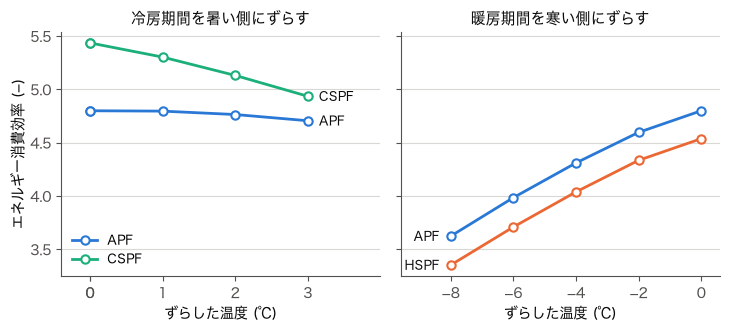

In [11]:
# 図: ずらした温度と効率の関係 (冷房・暖房を左右に分ける)
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4), sharey=True)
cases = (("冷房", "冷房期間を暑い側にずらす", "CSPF", AQUA, [0, 1, 2, 3]),
         ("暖房", "暖房期間を寒い側にずらす", "HSPF", ORANGE, [0, -2, -4, -6, -8]))
for ax, (period, title, spf, color, ds) in zip(axes, cases):

    # ずらさないケース (0 ℃) は基準ケースの値
    df = climate[climate["ずらした期間"] == period]
    x = [0] + [int(v) for v in df["ずらした温度 (℃)"]]
    apf = [base.f_ap] + list(df["APF"])
    s = [getattr(base.cooling if period == "冷房" else base.heating, "f_csp" if period == "冷房" else "f_hsp")] + list(df[spf])
    ax.plot(x, apf, color=BLUE, lw=2, marker="o", ms=6, mfc="white", mew=1.5, label="APF")
    ax.plot(x, s, color=color, lw=2, marker="o", ms=6, mfc="white", mew=1.5, label=spf)

    # 線の右端に名前を直接書く
    dx = 8 if period == "冷房" else -8
    ha = "left" if period == "冷房" else "right"
    ax.annotate("APF", (x[-1], apf[-1]), xytext=(dx, 0), textcoords="offset points", va="center", ha=ha, color=INK, fontsize=9)
    ax.annotate(spf, (x[-1], s[-1]), xytext=(dx, 0), textcoords="offset points", va="center", ha=ha, color=INK, fontsize=9)
    ax.set_title(title, color=INK, fontsize=10.5)
    ax.set_xlabel("ずらした温度 (℃)")
    ax.set_xticks(x)
    style(ax)

axes[0].set_ylabel("エネルギー消費効率 (−)")
axes[0].set_xlim(-0.4, 4.0)
axes[1].set_xlim(-9.6, 0.6)
axes[0].legend(loc="lower left", frameon=False, fontsize=9)
save(fig, "fig_climate")

## ケース 5: 最大モードの有無

基準ケースと暖房の能力特性が同じで、最大モードをもたない機種を作り、比べる。
最大モードをもたない機種の外気 2 ℃の着霜時の定格運転能力・消費電力には、基準ケースで係数から求まる値を与える
(ドキュメント 3 章 式 (77), (78), (81), (82), (85), (86) による)。
最大モードをもたない機種では、最大運転を定格運転と同じとみなす (ドキュメント 4 章、暫定)。

In [12]:
# 基準ケースの外気 2 ℃の着霜時の定格運転能力・消費電力を、3 章の式で求める
phi_m7 = 0.64 * BASE_H.phi_h_ful_7                       # 式 (85)
p_m7 = 0.82 * BASE_H.p_h_ful_7                           # 式 (86)
phi_2 = phi_m7 + (BASE_H.phi_h_ful_7 - phi_m7) * 9 / 14  # 式 (81)
p_2 = p_m7 + (BASE_H.p_h_ful_7 - p_m7) * 9 / 14          # 式 (82)
phi_f_2, p_f_2 = phi_2 / 1.12, p_2 / 1.06                # 式 (77), (78)

# 最大モードをもたない機種の入力値
NOMAX_H = HeatingInput(
    phi_c_ful_t100=2800, phi_h_ful_7=3600, p_h_ful_7=900, phi_h_haf_7=1800, p_h_haf_7=360,
    phi_h_ful_f_2=phi_f_2, p_h_ful_f_2=p_f_2,
)

rows = []
for d in (0, -4, -8):

    hours = shifted(TOKYO_HEATING_HOURS, d)
    for label, h in (("あり", BASE_H), ("なし", NOMAX_H)):

        r = compute_apf(BASE_C, h, None, hours)
        rows.append((f"{d:+d}", label, r.f_ap, r.heating.f_hsp, r.heating.c_hse / 1e3, heater_kwh(r)))

maxmode = pd.DataFrame(rows, columns=["暖房期間をずらした温度 (℃)", "最大モード", "APF", "HSPF",
                                      "暖房期間消費電力量 (kWh)", "補助電熱装置 (kWh)"])
save_table(pd.DataFrame({
    "暖房期間をずらした温度 (℃)": maxmode["暖房期間をずらした温度 (℃)"],
    "最大モード": maxmode["最大モード"],
    "APF": maxmode["APF"].map(lambda v: f"{v:.2f}"),
    "HSPF": maxmode["HSPF"].map(lambda v: f"{v:.2f}"),
    "暖房期間消費電力量 (kWh)": maxmode["暖房期間消費電力量 (kWh)"].map(lambda v: f"{v:,.0f}"),
    "補助電熱装置 (kWh)": maxmode["補助電熱装置 (kWh)"].map(lambda v: f"{v:,.1f}"),
}), "tab_maxmode")
print(f"Φh,ful,f(2) = {phi_f_2:.1f} W, Ph,ful,f(2) = {p_f_2:.1f} W")
maxmode

Φh,ful,f(2) = 2801.0 W, Ph,ful,f(2) = 794.5 W


,暖房期間をずらした温度 (℃),最大モード,APF,HSPF,暖房期間消費電力量 (kWh),補助電熱装置 (kWh)
0,+0,あり,4.797849,4.535953,782.045074,0.000000
1,+0,なし,4.796959,4.534767,782.249711,0.358857
2,-4,あり,4.308653,4.036625,1331.642572,0.000000
3,-4,なし,4.205956,3.917844,1372.015095,74.068821
4,-8,あり,3.621829,3.350529,2149.918225,20.637526
5,-8,なし,3.176706,2.885662,2496.260159,712.362598


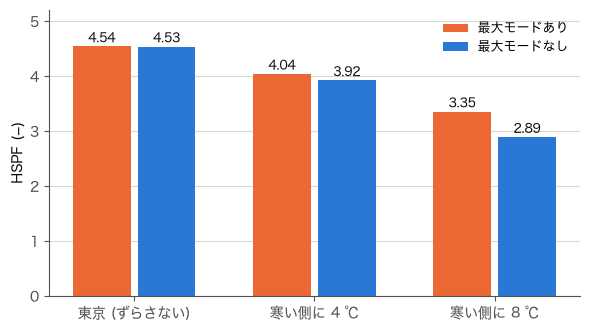

In [13]:
# 図: 最大モードの有無による HSPF の違い (暖房期間をずらした温度ごと)
fig, ax = plt.subplots(figsize=(6.0, 3.4))
ds = ["+0", "-4", "-8"]
w = 0.36
for i, (label, color) in enumerate((("あり", ORANGE), ("なし", BLUE))):

    vals = [maxmode[(maxmode["暖房期間をずらした温度 (℃)"] == d) & (maxmode["最大モード"] == label)]["HSPF"].iloc[0] for d in ds]
    xs = [j + (i - 0.5) * w for j in range(len(ds))]
    ax.bar(xs, vals, width=w - 0.04, color=color, label=f"最大モード{label}")
    for x, v in zip(xs, vals):

        ax.text(x, v + 0.05, f"{v:.2f}", ha="center", va="bottom", color=INK, fontsize=9)

ax.set_xticks(range(len(ds)), ["東京 (ずらさない)", "寒い側に 4 ℃", "寒い側に 8 ℃"])
ax.set_ylabel("HSPF (−)")
ax.set_ylim(0, 5.2)
style(ax)
ax.legend(loc="upper right", frameon=False, fontsize=9)
save(fig, "fig_maxmode")

## まとめ

各ケースの結果と考察は、ドキュメント 6 章「試算例」にまとめている。